# Crab fits with the histogram background on the DC4 mock data

Unbinned fits of the Crab in 3 h windows spread over the 3 months of DC4, with the
`hist_simple` response folded by `UnbinnedThreeMLPointSourceResponseTrapz` and the
data-driven `FreeNormHistBackgroundDensity`. The events are the simulated DC4 Crab (nebula +
pulsar) and the simulated DC4 background, which are available separately, so the fits can be
compared on the same Crab events:

- **signal only**: the Crab events alone (no background). The reference for the others: it
  only depends on the response and the folding (validated in `validation/closure/`).
- **bkg-only template**: Crab + background events, with the template built from the 3 months
  of the background simulation alone (an ideal template, without sources).
- **all-events template**: the same events, with the template built from the 3 months of
  the mock dataset (background + all the sources), as one would do with real data.
- **mock data** (first window only, the one of the Crab tutorial): the mock dataset itself,
  which also contains the other sources (~5% of the events), with the all-events template.

Cuts: Distance >= 1 cm (as the `hist_simple` response) and 200 keV - 5 MeV. The fitted model
is a power law, which is not exactly the injected spectrum; the comparison is between fits.

In [1]:
import gc
import time
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import astropy.units as u
from astropy.time import Time
from astromodels import Powerlaw, PointSource
from scipy.optimize import minimize

from cosipy.background_estimation import HistBackgroundTemplate, FreeNormHistBackgroundDensity
from cosipy.data_io.EmCDSUnbinnedData import (TimeTagEmCDSEventDataInSCFrameFromArrays,
                                              TimeTagEmCDSDistanceEventDataInSCFrameFromDC3Fits)
from cosipy.event_selection import DistanceSelector, ChainEventSelectors
from cosipy.event_selection.energy_selection import EnergySelector
from cosipy.event_selection.time_selection import TimeSelector
from cosipy.response.broadened_irf_cache import BroadenedIRFCache
from cosipy.response.relative_irf_hist import IRFRelativeHistUnpolarized
from cosipy.spacecraftfile import SpacecraftHistory
from cosipy.threeml.psr_fixed_ei import UnbinnedThreeMLPointSourceResponseTrapz

# divide-by-zero warnings of the empty phase-space bins, once per evaluation
warnings.filterwarnings('ignore', category=RuntimeWarning)

# threeML (imported by cosipy) sets a non-interactive backend without a display
%matplotlib inline


WARNING TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html



Inputs: the response, the orientation, the two 3-month templates
(`COSI-SMEX/develop/Data/Products_and_Templates/Background_Models/HistBackgroundTemplate/`,
Distance >= 1 cm), the week-4 mock dataset, and the simulated Crab and background events
(`Crab_DC4_3months...` and `Total_DC4_BG_3months...` in `COSI-SMEX/DC4/Data/`), extracted
in each window as arrays of the FITS columns.

In [2]:
data_path = Path('/home/user/dc4data')
irf_file = data_path / 'ResponseContinuum.area.relative.nonsparse_smoothing1p0.h5'
templates_files = {'bkg-only template': data_path / 'bkgonly_template_dist1cm.h5',
                   'all-events template': data_path / 'dc4_mock_bkg_template_dist1cm.h5'}
mock_file = data_path / 'dc4_mock_dataset_week_4_unbinned_data_filtered_with_SAAcut.fits.gz'
crab_file = data_path / 'crabfull/crab_all.npz'
windows = {'2028-03-23 10:36:00': data_path / 'truth/bkg_crabwin.npz'}
for start in (1836210468, 1838456868, 1839580068, 1840703268, 1841826468, 1842949668):
    windows[Time(start, format='unix').utc.iso[:19]] = data_path / f'windows/bkg_{start}.npz'

erange = (200., 5000.)
selection = EnergySelector(erange * u.keV)
sc_full = SpacecraftHistory.open(data_path / 'DC4_final_530km_3_month_with_slew_15sbins_GalacticEarth_SAA.fits')

spectrum = Powerlaw(index=-2.2, K=2.5e-6, piv=1000.)
spectrum.K.unit = 1 / u.cm ** 2 / u.s / u.keV
spectrum.piv.unit = u.keV
source = PointSource('Crab', l=184.56, b=-5.78, spectral_shape=spectrum)

irf = IRFRelativeHistUnpolarized.from_h5(irf_file, selections=selection)
cache = BroadenedIRFCache(IRFRelativeHistUnpolarized.from_h5(irf_file), energy_range_keV=(100., 10_000.))
cells = UnbinnedThreeMLPointSourceResponseTrapz.cells_for(source, cache, accuracy=1e-3)

# Smoothing chosen by cross-validation (see the HistBackgroundTemplate docs)
templates = {name: HistBackgroundTemplate.open(f).smooth(psichi_fwhm=4 * u.deg, phi_fwhm=20 * u.deg, time_counts=500)
             for name, f in templates_files.items()}

In [3]:
def load_events(filename, tstart, tstop):
    """Simulated events of a window as arrays, after the cuts"""
    z = np.load(filename)
    m = ((z['TimeTags'] >= tstart.utc.unix) & (z['TimeTags'] < tstop.utc.unix) & (z['Distance'] >= 1)
         & (z['Energies'] >= erange[0]) & (z['Energies'] < erange[1]))
    return {'unix': z['TimeTags'][m], 'energy': z['Energies'][m], 'lon': z['Chi local'][m],
            'lat': np.pi / 2 - z['Psi local'][m], 'phi': z['Phi'][m]}


def to_data(parts):
    arrays = {k: np.concatenate([p[k] for p in parts]) for k in parts[0]}
    t = Time(arrays['unix'], format='unix', scale='utc')
    return TimeTagEmCDSEventDataInSCFrameFromArrays(t.jd1, t.jd2, arrays['energy'], arrays['lon'], arrays['lat'],
                                                    arrays['phi'])


def mock_events(sc):
    cut = ChainEventSelectors(DistanceSelector(min_distance=1 * u.cm), TimeSelector(tstart=sc.tstart, tstop=sc.tstop),
                              selection)
    d = TimeTagEmCDSDistanceEventDataInSCFrameFromDC3Fits([mock_file], selection=cut)
    return {'unix': d.time.utc.unix, 'energy': np.asarray(d.energy_keV), 'lon': np.asarray(d.scattered_lon_rad_sc),
            'lat': np.asarray(d.scattered_lat_rad_sc), 'phi': np.asarray(d.scattering_angle_rad)}


def set_spectrum(log_k, index):
    spectrum.K.value = np.exp(log_k)
    spectrum.index.value = index


def fit(psr, idx, bkg_density=None, livetime=None, x0=(np.log(2.5e-6), -2.2, None)):
    """
    Maximum likelihood K, index (and background rate in Hz) with the events `idx`.
    `bkg_density` is the background density per Hz of rate, at all the events.
    """
    def negloglike(x):
        set_spectrum(x[0], x[1])
        s = np.asarray(psr.expectation_density())[idx]
        S = psr.expected_counts()
        if bkg_density is None:
            return -(np.sum(np.log(s)) - S)
        rate = np.exp(x[2])
        return -(np.sum(np.log(s + rate * bkg_density[idx])) - S - rate * livetime)

    start = list(x0[:2]) + ([] if bkg_density is None else [x0[2]])
    result = minimize(negloglike, start, method='Nelder-Mead', options=dict(xatol=1e-5, fatol=1e-4, maxiter=4000))
    errors = np.sqrt(np.diag(np.linalg.inv(hessian(negloglike, result.x))))
    set_spectrum(*result.x[:2])
    S = psr.expected_counts()
    return {'K': np.exp(result.x[0]), 'K error': np.exp(result.x[0]) * errors[0], 'index': result.x[1],
            'index error': errors[1], 'S': S, 'B': None if bkg_density is None else np.exp(result.x[2]) * livetime}


def hessian(f, x, step=1e-2):
    """Central finite differences"""
    n = len(x)
    h = np.zeros((n, n))
    for i in range(n):
        for j in range(i, n):
            def shifted(si, sj):
                y = np.array(x, dtype=float)
                y[i] += si * step
                y[j] += sj * step
                return f(y)
            h[i, j] = h[j, i] = (shifted(1, 1) - shifted(1, -1) - shifted(-1, 1) + shifted(-1, -1)) / (4 * step ** 2)
    return h

## Fits

The folding is computed once per window, for all the events of the window (Crab, background
and, in the first window, the mock data); each fit uses its own subset.

In [4]:
crab_all = None
results = []
t0 = time.time()
for w, (start, bkg_file) in enumerate(windows.items()):
    tstart = Time(start, scale='utc')
    tstop = tstart + 3 * u.h
    sc = sc_full.select_interval(tstart, tstop)
    livetime = sc.cumulative_livetime().to_value(u.s)

    parts = {'crab': load_events(crab_file, sc.tstart, sc.tstop), 'bkg': load_events(bkg_file, sc.tstart, sc.tstop)}
    if w == 0:
        parts['mock'] = mock_events(sc)
    sizes = [p['unix'].size for p in parts.values()]
    offsets = dict(zip(parts, np.cumsum([0] + sizes[:-1])))
    idx = {name: np.arange(offsets[name], offsets[name] + p['unix'].size) for name, p in parts.items()}
    data = to_data(list(parts.values()))

    set_spectrum(np.log(2.5e-6), -2.2)
    psr = UnbinnedThreeMLPointSourceResponseTrapz(data, irf, sc, cache, cells)
    psr.set_source(source)
    psr.init_cache()

    row = {'window': start, 'livetime': livetime, 'N crab': idx['crab'].size, 'N bkg': idx['bkg'].size}
    row['signal only'] = reference = fit(psr, idx['crab'])
    s_ref = np.asarray(psr.expectation_density())
    x0 = (np.log(reference['K']), reference['index'], np.log(idx['bkg'].size / livetime))
    both = np.concatenate([idx['crab'], idx['bkg']])
    for name, template in templates.items():
        bkg = FreeNormHistBackgroundDensity(data, sc, template, energy_selection=selection)
        density = np.asarray(bkg.expectation_density()) / bkg.parameters['bkg_norm'].to_value(u.Hz)
        # Template vs true background where the Crab is: sum of s/b over the true background
        # events, with b normalized to their number, is S if the template is right
        b = density * idx['bkg'].size / livetime
        row[name + ' s/b'] = np.sum(s_ref[idx['bkg']] / b[idx['bkg']]) / reference['S']
        row[name] = fit(psr, both, density, livetime, x0)
        if 'mock' in idx and name == 'all-events template':
            row['N mock'] = idx['mock'].size
            row['mock data'] = fit(psr, idx['mock'], density, livetime,
                                   (x0[0], x0[1], np.log(idx['mock'].size / livetime)))
        del bkg, density
    results.append(row)

    del psr, data
    gc.collect()
    print(f"{start}: {row['N crab']} Crab, {row['N bkg']} background events; {time.time() - t0:.0f} s", flush=True)

2028-03-23 10:36:00: 1894 Crab, 119242 background events; 415 s


2028-03-09 10:27:48: 1850 Crab, 111873 background events; 655 s


2028-04-04 10:27:48: 1589 Crab, 106522 background events; 966 s


2028-04-17 10:27:48: 2634 Crab, 105647 background events; 1305 s


2028-04-30 10:27:48: 2399 Crab, 106043 background events; 1541 s


2028-05-13 10:27:48: 2279 Crab, 106457 background events; 1778 s


2028-05-26 10:27:48: 1328 Crab, 107232 background events; 2173 s


In [5]:
cases = ['signal only', 'bkg-only template', 'all-events template']
print(f"{'window':20s}" + ''.join(f'{c:>32s}' for c in cases + ['mock data']))
for row in results:
    line = f"{row['window']:20s}"
    for c in cases + ['mock data']:
        if c in row:
            r = row[c]
            line += f"   K {r['K'] * 1e6:5.2f}e-6 idx {r['index']:+.2f} S {r['S']:6.0f}"
        else:
            line += ' ' * 32
    print(line)

print()
n = len(results)
for c in cases[1:]:
    pull_k = np.array([(row[c]['K'] - row['signal only']['K']) / row[c]['K error'] for row in results])
    pull_i = np.array([(row[c]['index'] - row['signal only']['index']) / row[c]['index error'] for row in results])
    k = np.array([row[c]['K'] / row['signal only']['K'] - 1 for row in results])
    ratio = np.array([row[c + ' s/b'] for row in results])
    print(f'{c:20s} K / K_signal_only - 1 = {k.mean():+.3f} (mean pull {pull_k.mean():+.2f} +- {1 / np.sqrt(n):.2f}),  '
          f'index pull {pull_i.mean():+.2f} +- {1 / np.sqrt(n):.2f};  sum(s/b) / S over the true background = '
          f'{ratio.mean():.3f} (windows: {", ".join(f"{r:.3f}" for r in ratio)})')
mock = results[0]['mock data']
print(f"mock data (first window): K / K_signal_only - 1 = {mock['K'] / results[0]['signal only']['K'] - 1:+.3f}, "
      f"index - signal only = {mock['index'] - results[0]['signal only']['index']:+.3f}, "
      f"B / (N_mock - N_crab) - 1 = {mock['B'] / (results[0]['N mock'] - results[0]['N crab']) - 1:+.4f}")

window                                   signal only               bkg-only template             all-events template                       mock data
2028-03-23 10:36:00    K  2.62e-6 idx -2.37 S   1894   K  1.30e-6 idx -2.83 S   1385   K  1.75e-6 idx -2.48 S   1383   K  0.77e-6 idx -2.79 S    792
2028-03-09 10:27:48    K  2.58e-6 idx -2.38 S   1850   K  0.94e-6 idx -3.02 S   1182   K  1.21e-6 idx -2.72 S   1160                                
2028-04-04 10:27:48    K  2.40e-6 idx -2.42 S   1589   K  0.95e-6 idx -2.99 S   1041   K  1.39e-6 idx -2.65 S   1119                                
2028-04-17 10:27:48    K  2.62e-6 idx -2.40 S   2633   K  1.33e-6 idx -2.96 S   2243   K  1.99e-6 idx -2.56 S   2286                                
2028-04-30 10:27:48    K  2.66e-6 idx -2.38 S   2399   K  1.67e-6 idx -2.61 S   1844   K  1.75e-6 idx -2.23 S   1403                                
2028-05-13 10:27:48    K  2.58e-6 idx -2.42 S   2279   K  1.23e-6 idx -2.98 S   1809   K  1.08e-6 idx -2.8

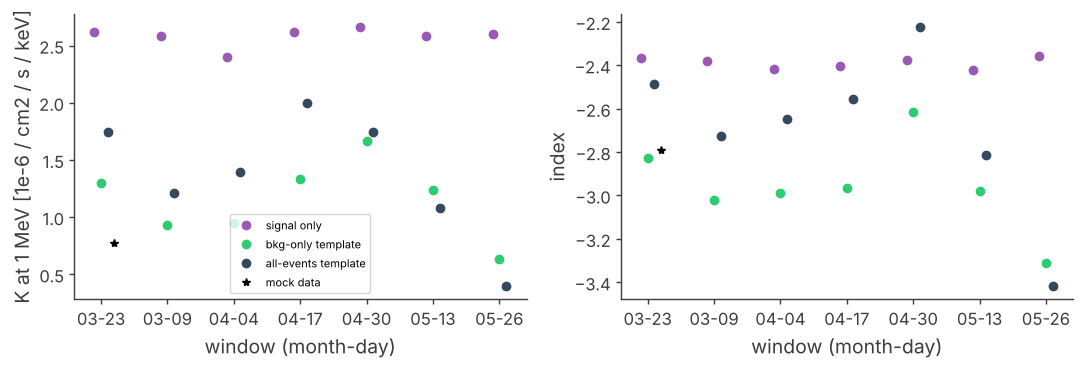

In [6]:
fig, axs = plt.subplots(1, 2, figsize=(11, 3.8))
x = np.arange(len(results))
for i, c in enumerate(cases):
    axs[0].plot(x + 0.1 * (i - 1), [row[c]['K'] * 1e6 for row in results], 'o', label=c)
    axs[1].plot(x + 0.1 * (i - 1), [row[c]['index'] for row in results], 'o', label=c)
axs[0].plot([0.2], [mock['K'] * 1e6], 'k*', label='mock data')
axs[1].plot([0.2], [mock['index']], 'k*', label='mock data')
axs[0].set_ylabel('K at 1 MeV [1e-6 / cm2 / s / keV]')
axs[1].set_ylabel('index')
for ax in axs:
    ax.set_xticks(x, [row['window'][5:10] for row in results])
    ax.set_xlabel('window (month-day)')
axs[0].legend(fontsize=8)
fig.tight_layout()

## Conclusion

The fits with the histogram background are biased low in every window (K about -50%, pulls
of -4 to -5 on average, softer index), although the template integrates exactly to its
expected counts and the folding is unbiased with an ideal background (`validation/closure/`).

The cause is how well the template describes the true background where the Crab is.
`sum(s/b) / S` over the true background events would be 1 for a perfect template; it is
about 0.98, i.e. the template overpredicts the background in the Crab's region of the data
space by ~2%. In a background-dominated fit the shift of the source counts is about
`(sum(s/b) / S - 1) sigma_S^2`, and with ~10^5 background events and `sigma_S` ~ 250 counts,
a 2% mismatch is enough to remove ~500 of ~2000 Crab counts. The template needs to match the
background in this projection to a few 0.1%. `sum(s/b) / S` measures it without fitting, so
it can be used to tune the template.